# Flexible Conversions: Power Plants for Two Fuels

The conversions of the previous notebooks had fixed conversion factors: per unit of electricity, a gas power plant always consumes the same amount of natural gas. This notebook shows two ways to make conversion factors more flexible:

| Topic | Parameters |
|---|---|
| Conversion factors that change over time or between regions | `commodityConversionFactors` with time series, per region or per investment period |
| A conversion that can choose between several fuels | a commodity group in `commodityConversionFactors`, `emissionFactors`, `flowShares` |

## 1. Conversion factors that change

Instead of a number, a conversion factor in `commodityConversionFactors` can also be

- a `pd.DataFrame` with one row per time step and one column per region, e.g. the coefficient of performance of a heat pump, which depends on the outside temperature,
- a `pd.Series` with one value per region, e.g. `{"electricity": -1, "hydrogen": pd.Series({"north": 0.72, "south": 0.68})}`,
- a dictionary with the investment periods as keys and one complete set of conversion factors per period, e.g. for electrolyzers that become more efficient over time: `{2020: {"electricity": -1, "hydrogen": 0.65}, 2030: {...}, 2040: {...}}`. All plants, old and new, then operate with the factors of the period they operate in.

## 2. Power plants for two fuels

Gas turbines can be built so that they burn natural gas, hydrogen or a mix of both. Such a power plant can choose its fuel in every hour. In FINE, this is a **flexible conversion**: the fuels that can replace each other form a **group** in `commodityConversionFactors`, a dictionary inside the dictionary:

```python
commodityConversionFactors={
    "electricity": 1,
    "fuel": {"naturalGas": -1 / 0.6, "hydrogen": -1 / 0.6},
}
```

The name of the group (here `"fuel"`) can be chosen freely. Per unit of electricity, the power plant consumes 1/0.6 units of natural gas, or 1/0.6 units of hydrogen, or a mix of both that adds up to one unit of operation. The operation of the plant is split into one part per fuel.

Two further parameters belong to flexible conversions:

- **`emissionFactors`**: the emissions per unit of each fuel consumed. With a flexible conversion, the CO<sub>2</sub> cannot be a fixed conversion factor, since it depends on the fuel. Here, 201 t (201×10<sup>-6</sup> million tonnes) of CO<sub>2</sub> per GWh of natural gas and nothing for hydrogen.
- **`flowShares`**: limits for the share of the operation that uses a fuel, with `"min"`, `"max"` or `"fix"` and values between 0 and 1, in every time step. They are given per investment period and can be left out for periods without a limit. We assume that the plants can burn at most 30 % hydrogen in 2030 and at most 50 % in 2040.

## 3. The model

We start from the basic tutorial with the hydrogen supply of the [Conversions notebook](13_conversions.ipynb) (demand, import and electrolyzers, added by `addHydrogenSupply` from `tutorialHelpers.py`). Then we replace the gas power plants with the flexible version: adding a component with the name of an existing one replaces it.

In [1]:
import warnings

import matplotlib.pyplot as plt
import pandas as pd

import fine as fn
from tutorialHelpers import COLORS, addHydrogenSupply, buildBasicTutorialModel

warnings.filterwarnings("ignore")  # keeps the output of this tutorial readable

esM = buildBasicTutorialModel(commodityUnits={"hydrogen": "GW_H2"})
addHydrogenSupply(esM)

esM.add(
    fn.Conversion(
        esM=esM,
        name="Gas power plants",
        physicalUnit="GW_el",
        commodityConversionFactors={
            "electricity": 1,
            "fuel": {"naturalGas": -1 / 0.6, "hydrogen": -1 / 0.6},
        },
        emissionFactors={"CO2": {"naturalGas": 201e-6}},  # Mt CO2 per GWh of fuel
        flowShares={  # at most 30 % hydrogen in 2030 and 50 % in 2040
            2030: {"max": {"hydrogen": 0.3}},
            2040: {"max": {"hydrogen": 0.5}},
        },
        hasCapacityVariable=True,
        investPerCapacity=650,  # million Euro per GW
        opexPerCapacity=20,
        interestRate=0.08,
        economicLifetime=30,
    )
)

In [2]:
esM.aggregateTemporally(n_clusters=8, segments=None)
esM.optimize(timeSeriesAggregation=True)

Set parameter OutputFlag to value 1


Set parameter Threads to value 3


Set parameter LogFile to value ""


Set parameter QCPDual to value 1


Gurobi Optimizer version 13.0.1 build v13.0.1rc0 (win64 - Windows 11+.0 (26300.2))


CPU model: Intel(R) Core(TM) Ultra 7 255U, instruction set [SSE2|AVX|AVX2]


... (81 outputs left out)

Solved with barrier


    4107    6.2402999e+05   0.000000e+00   0.000000e+00      1s


Solved in 4107 iterations and 0.83 seconds (0.80 work units)


Optimal objective  6.240299890e+05


## 4. Results

The operation per fuel is a variable of the optimization problem (`op_flex_conv` in `esM.pyM`), which the optimization summary does not show. Instead, we compute the fuel consumption from the summaries: the natural gas consumption follows from the CO<sub>2</sub> emissions, and the rest of the operation used hydrogen.

In [3]:
electricityByFuel = {}
for year in esM.investmentPeriodNames:
    conversions = esM.getOptimizationSummary("ConversionModel", outputLevel=1, ip=year)
    sourcesSinks = esM.getOptimizationSummary("SourceSinkModel", outputLevel=1, ip=year)
    operation = conversions.loc[("Gas power plants", "operation")].iloc[0].sum()
    emissions = sourcesSinks.loc[("CO2 to environment", "operation")].iloc[0].sum()
    naturalGas = emissions / 201e-6  # GWh of natural gas
    fromNaturalGas = naturalGas * 0.6  # GWh of electricity
    electricityByFuel[year] = {
        "Natural gas": fromNaturalGas / 1000,  # TWh
        "Hydrogen": (operation - fromNaturalGas) / 1000,
    }
electricityByFuel = pd.DataFrame(electricityByFuel).T.astype(float).clip(lower=0)
electricityByFuel.round(1)

,Natural gas,Hydrogen
2020,268.7,0.0
2030,134.3,0.0
2040,59.7,59.7


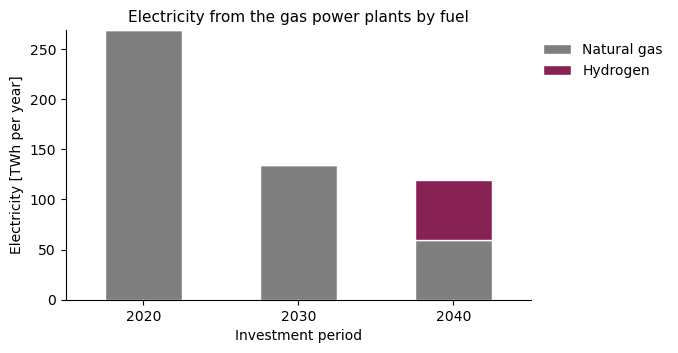

In [4]:
fig, ax = plt.subplots(figsize=(6, 3.5))
electricityByFuel.plot.bar(
    ax=ax,
    stacked=True,
    color=[COLORS["Natural gas import"], COLORS["Hydrogen import"]],
    edgecolor="white",
    rot=0,
    xlabel="Investment period",
    ylabel="Electricity [TWh per year]",
    title="Electricity from the gas power plants by fuel",
)
ax.legend(loc="upper left", bbox_to_anchor=(1, 1))

- In **2020 and 2030**, the power plants only burn natural gas. In 2030, they could burn up to 30 % hydrogen, but the model does not use this option.
- In **2040**, the CO<sub>2</sub> limit of 20 million tonnes allows about 60 TWh of electricity from natural gas (20 Mt / 201 t per GWh × 0.6). With hydrogen, the power plants produce another 60 TWh, twice as much as in the basic tutorial. The flow share is binding: in every hour, at most half of the electricity may come from hydrogen, so the hydrogen part can never be larger than the natural gas part.

Without the flexible conversion, the model would need a separate hydrogen power plant, as in the [Storages notebook](14_storages.ipynb), with its own capacity. Here, the same plants use both fuels.

## Things to try

- Remove the `flowShares`. Does the model burn more hydrogen in 2030?
- Make the hydrogen import cheaper in 2040, e.g. 60 Euro per MWh. How does the fuel mix change?
- Force a minimum share of hydrogen of 50 % in the north in 2040: `{2040: {"min": {"hydrogen": pd.Series({"north": 0.5})}}}`.

This is the last notebook of the series. The other **Examples** of the documentation show larger models and further features.